In [1]:
import matplotlib.pyplot as plt
from granad import *
import numpy as np
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

In [2]:
def goldene(au_s_hoppings, lattice_vectors):

    lattice_constant = 2.62 # Å
    lattice_basis = [[1, 0, 0], [-0.5, jnp.sqrt(3)/2, 0]] 

    #au_s_hoppings = [-0.21077006 + 1.1, -0.5814]   # PARAMETERS TUNED MANUALLY TO FIT THE EXPECTED ENERGY BAND :)

    goldene = (Material("Au")
            .lattice_constant(lattice_constant)  # Approximate lattice constant of hBN
            .lattice_basis(lattice_basis)
            .add_orbital_species("s_gold", atom='Au')
            .add_orbital(position=(0, 0), tag="Au_s", species="s_gold")
            .add_interaction(
                "hamiltonian",
                participants=("s_gold", "s_gold"),
                parameters=au_s_hoppings,  
            )   )

    flake = goldene.cut_flake(Rectangle(0.5, 0.5), minimum_neighbor_number = 0)
    fourier_cutoff = 4

    bulk = Periodic(flake, lattice_vectors, fourier_cutoff)
    return bulk

In [3]:
def get_energies(bulk):
    ### Calculate reciprocal basis vectors and plot them 
    A, B = bulk.reciprocal_basis.T
    A_norm = jnp.linalg.norm(A)
    B_norm = jnp.linalg.norm(B)

    ### Plot goldene's band structure along its high-symmetry path in k-space
    ks = jnp.concatenate(
        ( jnp.expand_dims(
            jnp.linspace(0,1/2,150),1)*A,  # Gamma -> M
        jnp.expand_dims(
            jnp.linspace(1/2,1/3,100),1)*A
            + jnp.expand_dims(jnp.linspace(0,1/3,100),1)*B, # M -> K
            jnp.expand_dims(
            jnp.linspace(1/3,0,200),1)*A
            + jnp.expand_dims(jnp.linspace(1/3,0,200),1)*B, # K -> Gamma
        ))
        
    ks = ks[::-1].T

    

    # Get eigenvalues along the path and plot
    energies, eigenvectors = bulk.get_eigenbasis(ks)
    return energies, eigenvectors, ks

In [4]:
def find_fermi_contour(
    bulk, au_s_hoppings, lattice_vectors, mu, accuracy, 
    N_monkhorst, show_plot=False, filename=None):
        
    # Prepare output filename
    print(f"Saving output file as {filename}.csv")

    # Iterate over points in k-space (Monkhorst-Pack cell) 
    # and check for every point if it corresponds to Fermi energy (mu) within given accuracy
    ks = bulk.get_kgrid_monkhorst_pack([N_monkhorst, N_monkhorst])
    fermi_contour = []
    fermi_energies = []
    energy_band = []
    a1 = lattice_vectors[0]
    a2 = lattice_vectors[1]

    with open(f"../../outputs/fermi_contours/{filename}.csv", "w") as output_file:
        for idx, coordinates in enumerate(ks.T):
            if not idx % 10000:
                print(f"{idx} of {len(ks.T)}")
            kx, ky, kz = coordinates
            energy = (2 * au_s_hoppings[1] * (
                np.cos(kx * a1[0] + ky * a1[1]) + 
                np.cos(kx * a2[0] + ky * a2[1]) + 
                np.cos(kx * (a1[0] + a2[0]) + ky * (a1[1] + a2[1]) ) ) )
            if abs(energy - mu) < accuracy:
                fermi_contour.append([float(kx), float(ky), float(kz)])
                fermi_energies.append(energy)
                output_file.write(f"{float(kx)},{float(ky)},{float(kz)}\n")
            energy_band.append(energy)

    if show_plot:
        fig, ax = plt.subplots()
        for k_value in fermi_contour:
            ax.scatter(k_value[0], k_value[1], s = 5, color = "blue")
        ax.set_aspect("equal")
        plt.title(f"hoppings: {au_s_hoppings}, E_F: {mu}, accuracy={accuracy}")
        plt.tight_layout()
        if filename:
            plt.savefig(f"../../imgs/fermi_contours/{filename}.jpg")
        plt.show()

    return np.array(fermi_contour), fermi_energies

In [5]:
def plot_velocities(fermi_contour, v, title=None, filename=None):

    vx = v[0,:,0,0].real / (2*-0.58)
    vy = v[1,:,0,0].real / (2*-0.58)
    vz = v[2,:,0,0].real / (2*-0.58)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    fermi_arr = np.array(fermi_contour.T)
    axes[0].set_xlabel("k_x")
    axes[0].set_ylabel("k_y")
    plot1 = axes[0].scatter(fermi_arr[0, :], fermi_arr[1, :], c=vx.real, s=2, cmap="coolwarm", label="dE/dk_x")
    axes[0].set_aspect("equal")
    plt.colorbar(plot1, ax=axes[0])

    axes[1].set_xlabel("k_x")
    axes[1].set_ylabel("k_y")
    plot2 = axes[1].scatter(fermi_arr[0, :], fermi_arr[1, :], c=vy.real, s=2, cmap="coolwarm", label="dE/dk_y")
    axes[1].set_aspect("equal")
    plt.colorbar(plot2, ax=axes[1])

    fermi_arr = np.array(fermi_contour.T)
    axes[2].set_xlabel("k_x")
    axes[2].set_ylabel("k_y")
    plot3 = axes[2].scatter(fermi_arr[0, :], fermi_arr[1, :], c=vx.real**2+vy.real**2, s=2, label="sqrt (dE/dk_x)^2 + (dE/dk_y)^2")
    axes[2].set_aspect("equal")
    plt.colorbar(plot3, ax=axes[2])

    plt.suptitle(title)

    plt.tight_layout()
    if filename:
        plt.savefig(f"../../imgs/velocities/{filename}.png")
    plt.show()


Mu on entire MP is 0.9704060032026947
Saving output file as goldene_0.65_-0.90_mu0.9704_acc0.01_N399.csv
0 of 159201
10000 of 159201
20000 of 159201
30000 of 159201
40000 of 159201
50000 of 159201
60000 of 159201
70000 of 159201
80000 of 159201
90000 of 159201
100000 of 159201
110000 of 159201
120000 of 159201
130000 of 159201
140000 of 159201
150000 of 159201


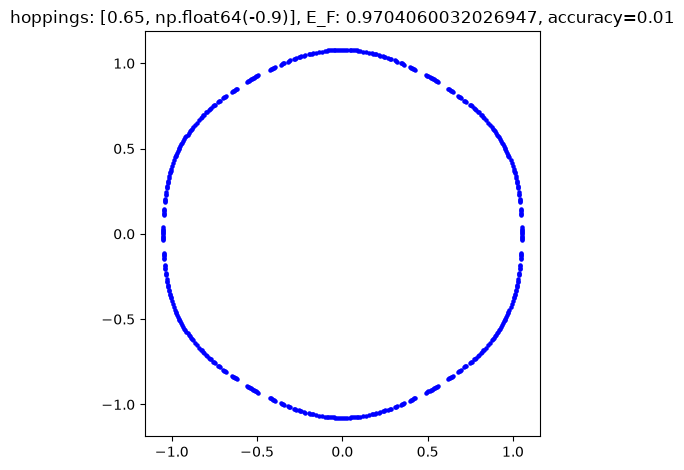

Found Fermi contour with 528 points.
(528, 3)


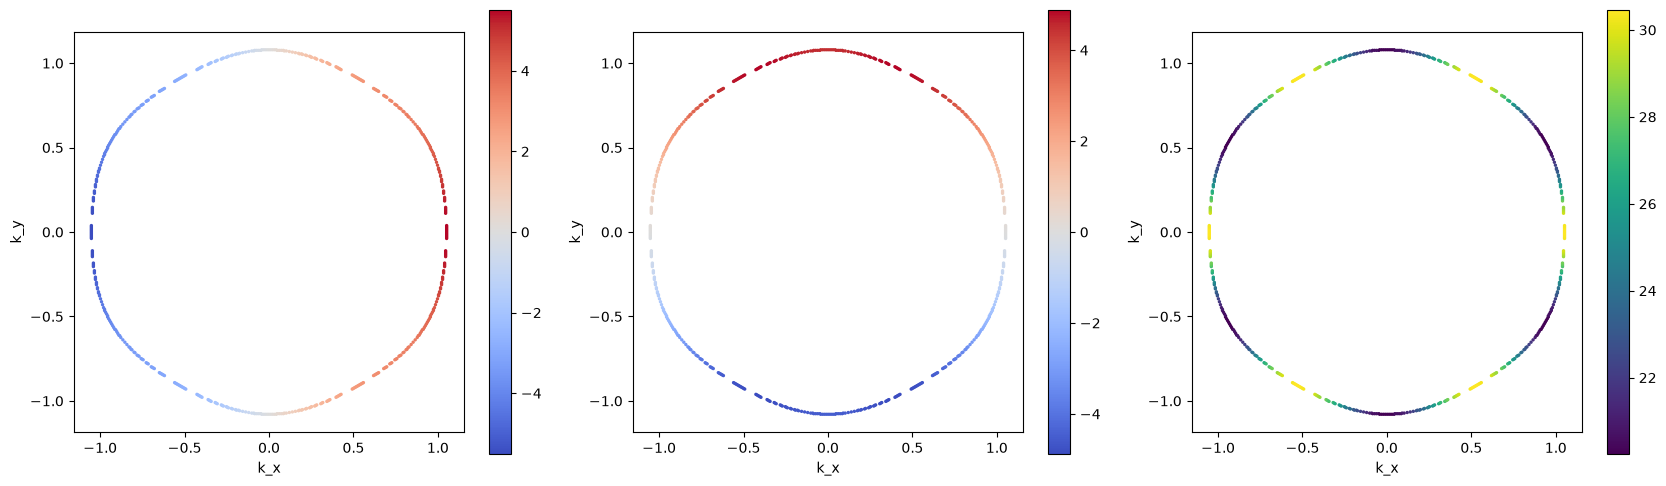

--- au_s_hoppings: [0.65, np.float64(-0.9)] ---
 mu on total Monkhorst-Pack: 0.9704060032026947

Mu on entire MP is 1.006006670225216
Saving output file as goldene_0.65_-1.00_mu1.0060_acc0.01_N399.csv
0 of 159201
10000 of 159201
20000 of 159201
30000 of 159201
40000 of 159201
50000 of 159201
60000 of 159201
70000 of 159201
80000 of 159201
90000 of 159201
100000 of 159201
110000 of 159201
120000 of 159201
130000 of 159201
140000 of 159201
150000 of 159201


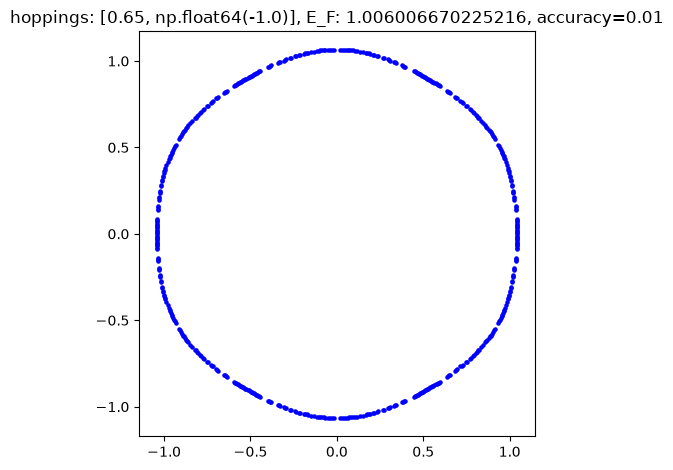

Found Fermi contour with 540 points.
(540, 3)


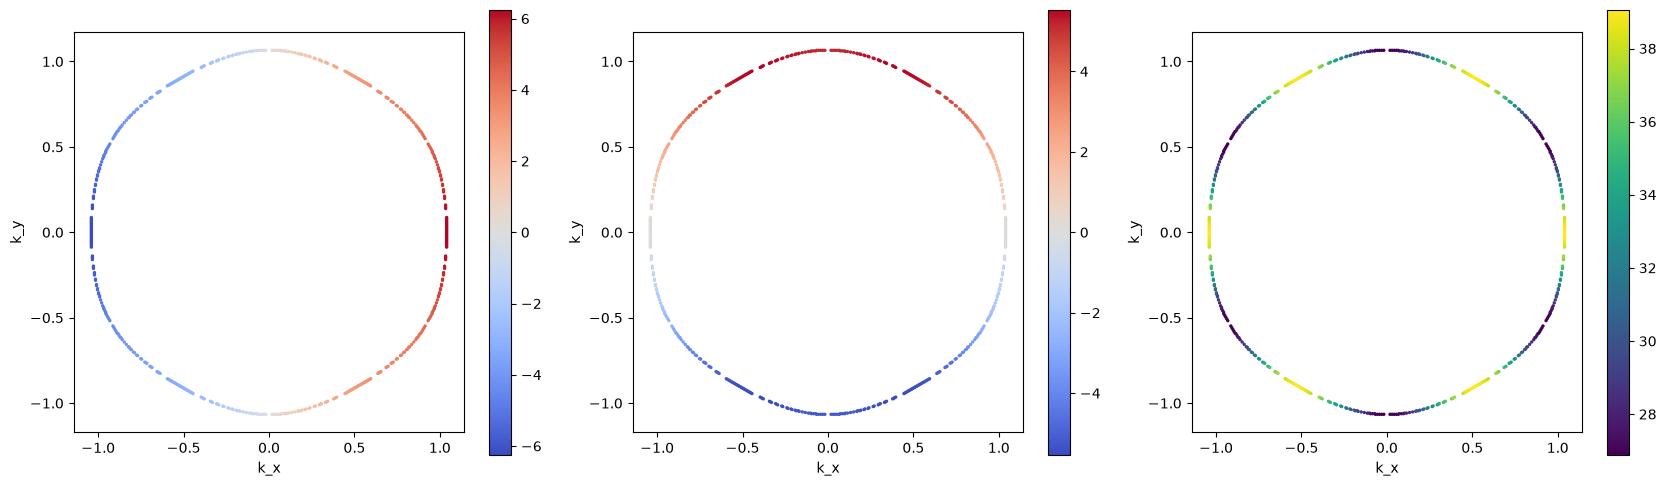

--- au_s_hoppings: [0.65, np.float64(-1.0)] ---
 mu on total Monkhorst-Pack: 1.006006670225216



In [6]:
onsite = 0.65
N_monkhorst = 399
accuracy = 1e-2
lattice_constant = 2.62
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])

nn_hoppings = np.linspace(-0.9, -1, 2)
au_s_hoppings_list = [[onsite, nn_hopping] for nn_hopping in nn_hoppings]

for au_s_hoppings in au_s_hoppings_list:

    bulk = goldene(au_s_hoppings, lattice_vectors)
    energies, eigenvectors, ks = get_energies(bulk)
    mu = bulk.get_mu(energies)
    print(f"Mu on entire MP is {mu}")
    
    filename = f"goldene_{au_s_hoppings[0]:.2f}_{au_s_hoppings[1]:.2f}_mu{mu:.4f}_acc{accuracy}_N{N_monkhorst}"
    
    fermi_contour, fermi_energies = find_fermi_contour(
        bulk, au_s_hoppings, lattice_vectors, mu, accuracy, 
        N_monkhorst, show_plot=True, filename=filename)
    print(f"Found Fermi contour with {len(fermi_contour)} points.")
    print(fermi_contour.shape)

    energies_contour, vecs_contour = bulk.get_eigenbasis(fermi_contour.T)
    v = bulk.get_velocity_operator(fermi_contour.T, vecs_contour)
    plot_velocities(fermi_contour, v, filename=filename)

    print(f"--- au_s_hoppings: {au_s_hoppings} ---\n mu on total Monkhorst-Pack: {mu}\n")

# plt.axvline(200/450, c='tab:green', label="K")
# plt.axvline(300/450, c='tab:purple', label="M")
# plt.axhline(0)
# plt.ylim(-3.5, 3.5)
# plt.legend()
# plt.show()

Mu on entire MP is 1.416859963846524


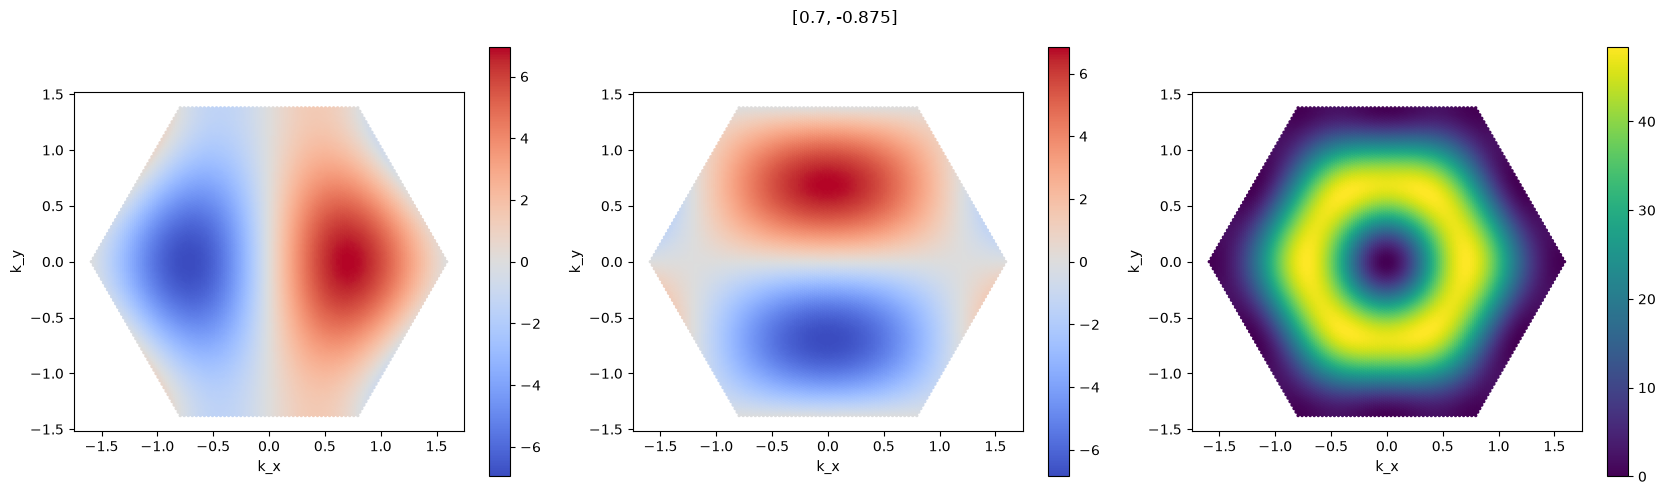

In [7]:
onsite = 0
N_monkhorst = 399
accuracy = 1e-2
lattice_constant = 2.62
lattice_vectors = lattice_constant*jnp.array([
    [1, 0, 0],
    [-0.5, jnp.sqrt(3)/2, 0] ])

au_s_hoppings = [0.7, -0.875]

bulk = goldene(au_s_hoppings, lattice_vectors)
ks = bulk.get_first_brillouin_zone([399, 399])
energies, eigenvectors = bulk.get_eigenbasis(ks)
mu = bulk.get_mu(energies)
print(f"Mu on entire MP is {mu}")

# energies_contour, vecs_contour = bulk.get_eigenbasis(fermi_contour.T)
v = bulk.get_velocity_operator(ks, eigenvectors)
plot_velocities(ks.T, v, title=f"{au_s_hoppings}", filename=f"full_{au_s_hoppings}")
